In [2]:
# Install the packages needed to work with Excel data.
#%pip install pandas numpy matplotlib openpyxl

# Import pandas to work with Excel data.
import pandas as pd

# Read the Excel file.
df = pd.read_excel("AI_Readiness_Text_Responses_10_Clients.xlsx")

# Display the first five rows.
df.head()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 81.7 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 355.2/355.2 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 180.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 101.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 109.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 33.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


,Client_ID,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20
0,C001,Agree,Agree,Neutral,Neutral,Neutral,Neutral,Neutral,Strongly agree,Strongly agree,...,Strongly agree,Neutral,Strongly agree,Agree,Strongly agree,Disagree,Agree,Agree,Daily,Inaccurate answers
1,C002,Strongly agree,Strongly agree,Neutral,Neutral,Strongly agree,Agree,Strongly agree,Strongly agree,Strongly agree,...,Strongly agree,Strongly agree,Neutral,Strongly agree,Strongly agree,Strongly agree,Agree,Strongly agree,Several times a week,Privacy of customer data
2,C003,Neutral,Strongly disagree,NaN,Agree,Neutral,Agree,Strongly disagree,Disagree,Neutral,...,Agree,Strongly disagree,Neutral,Strongly disagree,Disagree,Agree,Neutral,Disagree,Weekly,Job security
3,C004,Strongly agree,Strongly agree,Strongly agree,Strongly agree,6,Strongly agree,Agree,Neutral,Strongly agree,...,Agree,Strongly agree,Agree,Strongly agree,Strongly agree,Agree,Strongly agree,Strongly agree,Rarely,Not enough training
4,C005,Agree,Strongly agree,Strongly agree,Strongly agree,Strongly agree,Agree,Agree,Agree,Neutral,...,Agree,Strongly agree,Strongly agree,Strongly agree,Strongly agree,Strongly agree,Agree,Strongly agree,Never,Bias in recommendations


In [3]:
# Count missing values in each column.
df.isnull().sum()

Client_ID    0
Q1           0
Q2           0
Q3           1
Q4           0
Q5           0
Q6           0
Q7           0
Q8           0
Q9           0
Q10          0
Q11          0
Q12          1
Q13          0
Q14          0
Q15          0
Q16          0
Q17          0
Q18          0
Q19          0
Q20          1
dtype: int64

  Client_ID       Q1       Q2                 Q3                 Q4  \
5      C006       4   Neutral  Strongly disagree            Neutral   
6      C006  Neutral  Neutral  Strongly disagree  Strongly disagree   

                  Q5       Q6       Q7        Q8       Q9  ...      Q11  \
5            Neutral  Neutral  Neutral  Disagree    Agree  ...  Neutral   
6  Strongly disagree  Neutral    Agree   Neutral  Neutral  ...  Neutral   

       Q12       Q13      Q14                Q15                Q16      Q17  \
5  Neutral  Disagree  Neutral  Strongly disagree  Strongly disagree  Neutral   
6  Neutral   Neutral  Neutral            Neutral           Disagree  Neutral   

       Q18                 Q19                 Q20  
5    Agree               daily                 NaN  
6  Neutral  2-3 times per week  AI making mistakes  

[2 rows x 21 columns]


In [7]:
# Create a list of Likert questions.
questions = [f"Q{i}" for i in range(1, 19)]
questions



['Q1',
 'Q2',
 'Q3',
 'Q4',
 'Q5',
 'Q6',
 'Q7',
 'Q8',
 'Q9',
 'Q10',
 'Q11',
 'Q12',
 'Q13',
 'Q14',
 'Q15',
 'Q16',
 'Q17',
 'Q18']

In [8]:
#Why recode?
#1. Calculate statistics: We can calculate average scores, medians, and response distributions.
#2. Compare questions: We can compare employee confidence in AI with their perceptions of leadership support.
#3. Create visualizations: Numeric values make it easier to create certain charts and summarize responses.
#4. Ensure consistency: Different spellings or capitalization of the same response can be standardized before recoding.
# Create a dictionary to convert responses to numbers.
likert_scale = {
    "strongly disagree": 1,
    "disagree": 2,
    "neutral": 3,
    "agree": 4,
    "strongly agree": 5
}



In [10]:

# Go through each Likert question.
for question in questions:

    # Convert responses to text.
    df[question] = df[question].astype("string")

    # Remove extra spaces and make all text lowercase.
    df[question] = df[question].str.strip().str.lower()

    # Replace text responses with numeric values.
    df[question] = df[question].map(likert_scale)

# Display the recoded data.
df.head()

,Client_ID,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20
0,C001,4.0,4,3.0,3,3.0,3,3,5,5,...,5,3.0,5,4,5,2,4,4.0,Daily,Inaccurate answers
1,C002,5.0,5,3.0,3,5.0,4,5,5,5,...,5,5.0,3,5,5,5,4,5.0,Several times a week,Privacy of customer data
2,C003,3.0,1,NaN,4,3.0,4,1,2,3,...,4,1.0,3,1,2,4,3,2.0,Weekly,Job security
3,C004,5.0,5,5.0,5,NaN,5,4,3,5,...,4,5.0,4,5,5,4,5,5.0,Rarely,Not enough training
4,C005,4.0,5,5.0,5,5.0,4,4,4,3,...,4,5.0,5,5,5,5,4,5.0,Never,Bias in recommendations


In [11]:
# Remove extra spaces and standardize capitalization.
df["Q19"] = df["Q19"].astype("string").str.strip().str.lower()

# Make different ways of saying the same thing consistent.
df["Q19"] = df["Q19"].replace({
    "every day": "daily",
    "2-3 times per week": "several times a week",
    "once a week": "weekly"
})

# Display the cleaned responses.
print(df["Q19"])

0                   daily
1    several times a week
2                  weekly
3                  rarely
4                   never
5                   daily
6    several times a week
7                  weekly
8                   daily
9                 monthly
Name: Q19, dtype: string


In [12]:
# Remove extra spaces from written answers.
df["Q20"] = df["Q20"].astype("string").str.strip()

# Display the responses.
print(df["Q20"])

0          Inaccurate answers
1    Privacy of customer data
2                Job security
3         Not enough training
4     Bias in recommendations
5                        <NA>
6          AI making mistakes
7        Lack of transparency
8        Data confidentiality
9              Privcy of data
Name: Q20, dtype: string


In [13]:
# Save the cleaned dataset to a new Excel file.
df.to_excel("AI_Readiness_Cleaned.xlsx", index=False)

# Display a confirmation message.
print("Data cleaning complete!")

#What was accomplished: We imported the Excel file, checked for missing values and duplicates, converted Likert responses to numbers, standardized AI usage responses, and saved a cleaned dataset.

#NOTE: Cleaning data is not the same as analyzing data. Cleaning makes sure the information is consistent, usable, and reliable before we begin drawing conclusions for organizational leadership. Using a different file, practice preparing your data for analysis by cleaning it. Share your Python file with the code and the data with me when complete.


Data cleaning complete!


Now that you've cleaned and saved your dataset, we can begin exploratory data analysis (EDA).
Since the dataset has only 10 respondents, we'll start with descriptive statistics rather than complex statistical tests.


In [14]:
# Install the package for creating charts.
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [15]:
# Import matplotlib for creating charts.
import matplotlib.pyplot as plt

In [16]:
# Create a list of survey questions 1 through 18.
questions = [f"Q{i}" for i in range(1, 19)]

# Calculate the average score for each question.
averages = df[questions].mean()

# Round the averages to two decimal places.
averages = averages.round(2)

# Display the results.
print(averages)

Q1     3.67
Q2     3.30
Q3     3.00
Q4     3.20
Q5     2.78
Q6     3.40
Q7     3.00
Q8     3.00
Q9     3.30
Q10    3.50
Q11    3.60
Q12    3.22
Q13    3.20
Q14    3.30
Q15    3.40
Q16    3.30
Q17    3.40
Q18    3.67
dtype: float64


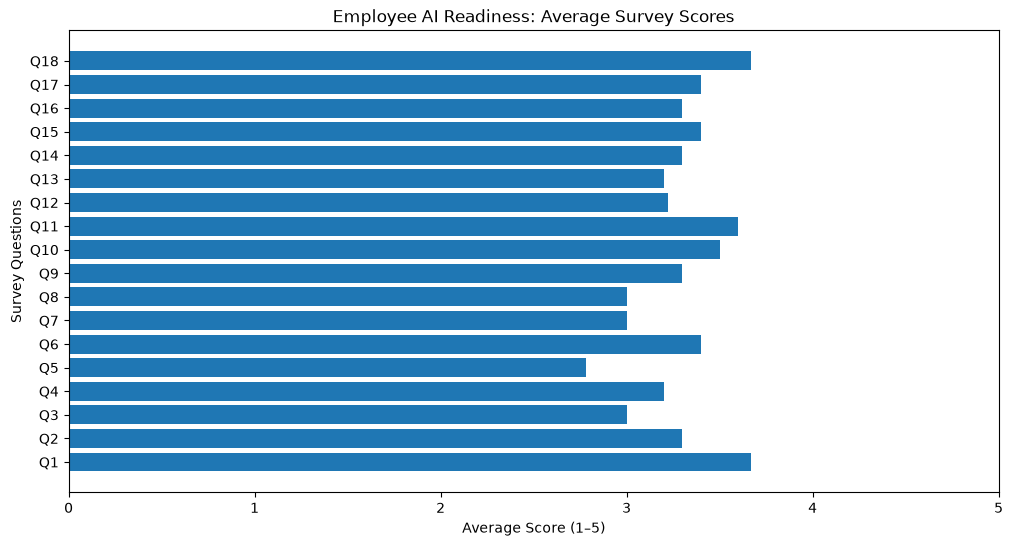

In [17]:
# Set the size of the chart.
plt.figure(figsize=(12, 6))

# Create a horizontal bar chart of average scores.
plt.barh(averages.index, averages.values)

# Add a title.
plt.title("Employee AI Readiness: Average Survey Scores")

# Label the horizontal axis.
plt.xlabel("Average Score (1–5)")

# Label the vertical axis.
plt.ylabel("Survey Questions")

# Set the scale from 0 to 5.
plt.xlim(0, 5)

# Display the chart.
plt.show()

In [18]:
# Sort the average scores from lowest to highest.
lowest_scores = averages.sort_values()

# Select the five lowest scores.
bottom_five = lowest_scores.head(5)

# Display the results.
print(bottom_five)

Q5    2.78
Q3    3.00
Q7    3.00
Q8    3.00
Q4    3.20
dtype: float64


In [20]:
# Check which answers are 4 or 5.
favorable = df[questions].isin([4, 5])

# Count favorable answers for each question.
favorable_count = favorable.sum()

# Count valid answers for each question.
total_responses = df[questions].count()

# Calculate the favorable percentage.
favorable_percent = (favorable_count / total_responses) * 100

# Round the percentages.
favorable_percent = favorable_percent.round(1)

# Display the results.
print(favorable_percent)

Q1     44.4
Q2     40.0
Q3     33.3
Q4     40.0
Q5     22.2
Q6     50.0
Q7     50.0
Q8     30.0
Q9     40.0
Q10    30.0
Q11    60.0
Q12    33.3
Q13    40.0
Q14    40.0
Q15    40.0
Q16    50.0
Q17    50.0
Q18    55.6
dtype: float64


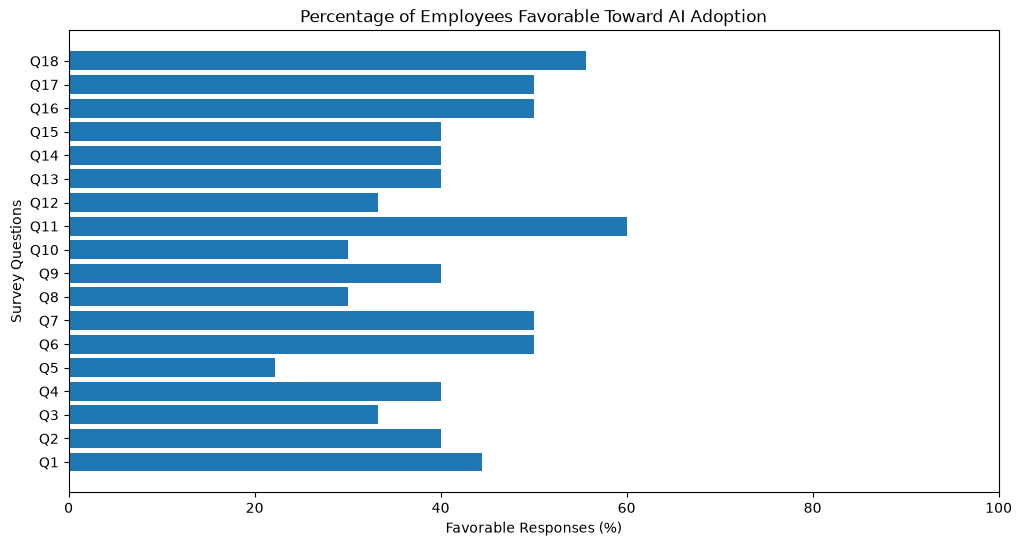

In [21]:
# Create a chart.
plt.figure(figsize=(12, 6))

# Draw a horizontal bar chart.
plt.barh(favorable_percent.index, favorable_percent.values)

# Add a title.
plt.title("Percentage of Employees Favorable Toward AI Adoption")

# Label the horizontal axis.
plt.xlabel("Favorable Responses (%)")

# Label the vertical axis.
plt.ylabel("Survey Questions")

# Set the percentage scale.
plt.xlim(0, 100)

# Display the chart.
plt.show()

In [22]:
# Count how many employees selected each frequency.
usage_counts = df["Q19"].value_counts()

# Display the counts.
print(usage_counts)

Q19
daily                   3
several times a week    2
weekly                  2
rarely                  1
never                   1
monthly                 1
Name: count, dtype: Int64


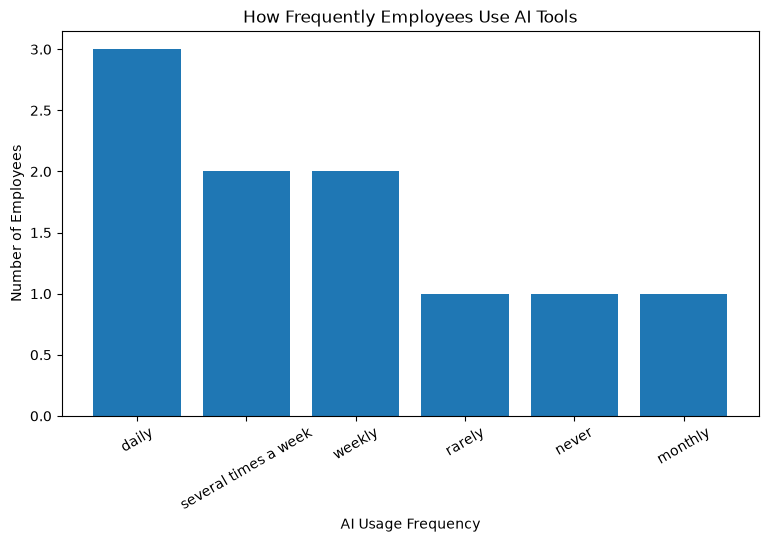

In [23]:
#Create the Chart
# Set the chart size.
plt.figure(figsize=(9, 5))

# Create a bar chart of AI usage frequency.
plt.bar(usage_counts.index, usage_counts.values)

# Add a title.
plt.title("How Frequently Employees Use AI Tools")

# Label the horizontal axis.
plt.xlabel("AI Usage Frequency")

# Label the vertical axis.
plt.ylabel("Number of Employees")

# Rotate category labels to make them readable.
plt.xticks(rotation=30)

# Display the chart.
plt.show()